In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

from scipy.cluster.hierarchy import linkage, dendrogram

# Load dataset
df = pd.read_csv("indian_roads_dataset.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (20000, 24)


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


In [99]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nData types:")
print(df.dtypes)

Number of rows: 20000
Number of columns: 24

Missing values:
festival       19885
accident_id        0
state              0
city               0
longitude          0
date               0
time               0
latitude           0
hour               0
day_of_week        0
dtype: int64

Data types:
accident_id            int64
city                     str
state                    str
latitude             float64
longitude            float64
date                     str
time                     str
hour                   int64
day_of_week              str
is_weekend             int64
road_type                str
lanes                  int64
traffic_signal         int64
weather                  str
visibility               str
temperature            int64
traffic_density          str
cause                    str
accident_severity        str
vehicles_involved      int64
casualties             int64
is_peak_hour           int64
festival                 str
risk_score           float64
dtype: 

In [100]:
numeric_features = [
    "latitude", "longitude", "hour", "is_weekend",
    "lanes", "traffic_signal", "temperature",
    "vehicles_involved", "casualties",
    "is_peak_hour", "risk_score"
]

categorical_features = [
    "day_of_week", "road_type", "weather",
    "visibility", "traffic_density", "cause",
    "accident_severity"
]

# Select useful features
data = df[numeric_features + categorical_features].copy()

# Use a reproducible sample to make clustering faster
data = data.sample(
    n=min(3000, len(data)),
    random_state=42
)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X = preprocessor.fit_transform(data)
X = X.toarray() if hasattr(X, "toarray") else X

print("Processed data shape:", X.shape)

Processed data shape: (3000, 38)


In [101]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print(
    "Variance explained by 2 components:",
    round(pca.explained_variance_ratio_.sum(), 3)
)

def plot_clusters(labels, title):
    labels = np.asarray(labels)

    plt.figure(figsize=(8, 5))

    # Plot normal clusters
    normal = labels != -1
    if normal.any():
        scatter = plt.scatter(
            X_pca[normal, 0],
            X_pca[normal, 1],
            c=labels[normal],
            cmap="tab10",
            s=15,
            alpha=0.7
        )
        plt.colorbar(scatter, label="Cluster")

    # DBSCAN noise points
    if (~normal).any():
        plt.scatter(
            X_pca[~normal, 0],
            X_pca[~normal, 1],
            c="black",
            marker="x",
            s=20,
            label="Noise"
        )
        plt.legend()

    plt.title(title)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.tight_layout()
    plt.show()

Variance explained by 2 components: 0.211


In [102]:
results = []

def evaluate_model(name, labels):
    labels = np.asarray(labels)

    # DBSCAN labels noise points as -1
    valid = labels != -1
    X_eval = X[valid]
    labels_eval = labels[valid]

    clusters = np.unique(labels_eval)
    n_clusters = len(clusters)

    silhouette = np.nan
    dbi = np.nan

    # Metrics require at least 2 clusters
    if 2 <= n_clusters < len(labels_eval):
        silhouette = silhouette_score(X_eval, labels_eval)
        dbi = davies_bouldin_score(X_eval, labels_eval)

    noise_count = np.sum(labels == -1)

    results.append({
        "Algorithm": name,
        "Number of Clusters": n_clusters,
        "Noise Points": int(noise_count),
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": dbi
    })

    print("Algorithm:", name)
    print("Number of Clusters:", n_clusters)
    print("Noise Points:", noise_count)
    print("Silhouette Score:", silhouette)
    print("Davies-Bouldin Index:", dbi)

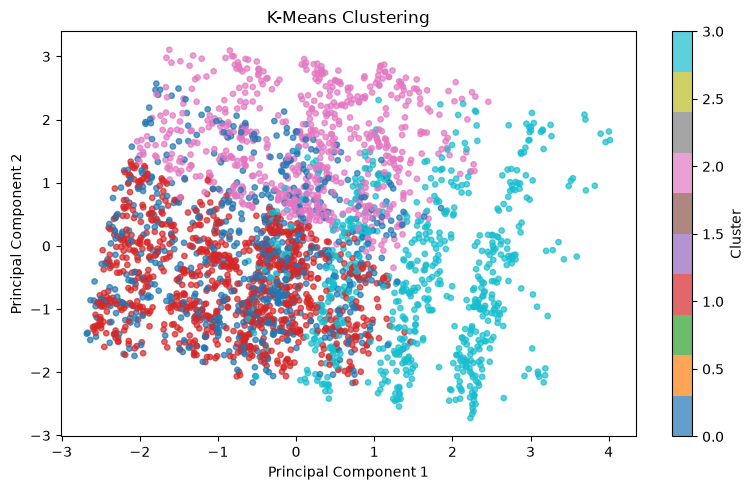

Algorithm: K-Means
Number of Clusters: 4
Noise Points: 0
Silhouette Score: 0.07705182760191034
Davies-Bouldin Index: 2.867274558036133


In [103]:
# Apply K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

# Plot clusters
plot_clusters(kmeans_labels, "K-Means Clustering")

# Evaluate results
evaluate_model("K-Means", kmeans_labels)

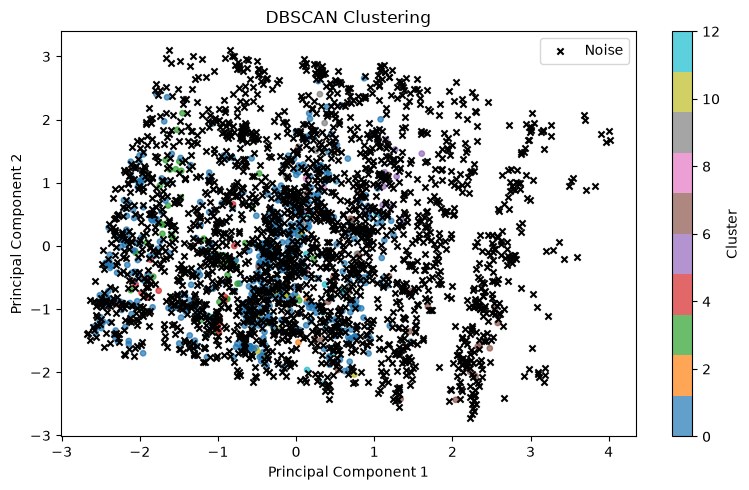

Algorithm: DBSCAN
Number of Clusters: 13
Noise Points: 2314
Silhouette Score: 0.006149270050970795
Davies-Bouldin Index: 1.9751557828562745


In [104]:
# Apply DBSCAN
dbscan = DBSCAN(
    eps=3.0,
    min_samples=12
)

dbscan_labels = dbscan.fit_predict(X)

# Plot clusters
plot_clusters(dbscan_labels, "DBSCAN Clustering")

# Evaluate results
evaluate_model("DBSCAN", dbscan_labels)

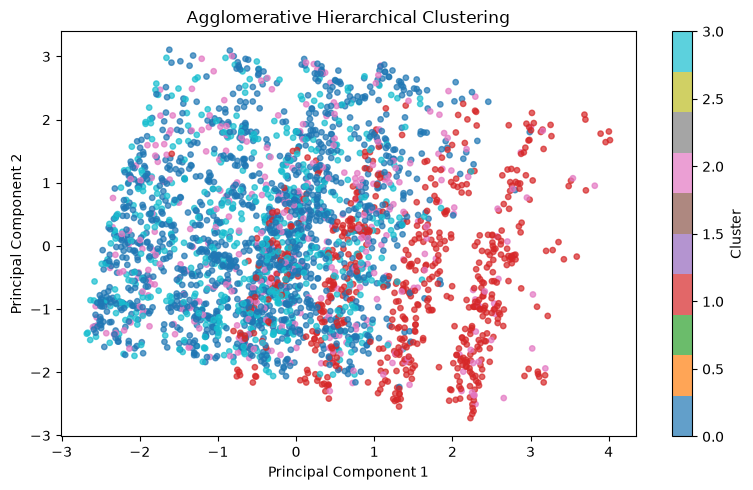

Algorithm: Agglomerative
Number of Clusters: 4
Noise Points: 0
Silhouette Score: 0.08041508201473938
Davies-Bouldin Index: 2.9509294398008605


In [105]:
# Apply Agglomerative Clustering
agg = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

agg_labels = agg.fit_predict(X)

# Plot clusters
plot_clusters(
    agg_labels,
    "Agglomerative Hierarchical Clustering"
)

# Evaluate results
evaluate_model("Agglomerative", agg_labels)

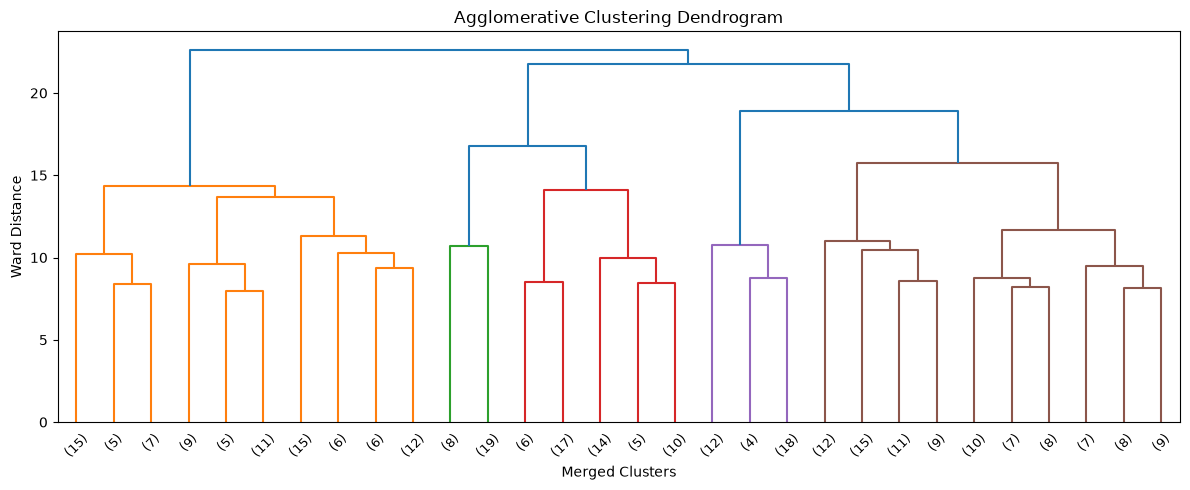

In [106]:
# Select a smaller sample for the dendrogram
rng = np.random.default_rng(42)
indices = rng.choice(
    len(X),
    size=min(300, len(X)),
    replace=False
)

X_dendrogram = X[indices]

# Create hierarchical linkage
Z = linkage(X_dendrogram, method="ward")

# Plot dendrogram
plt.figure(figsize=(12, 5))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=9
)

plt.title("Agglomerative Clustering Dendrogram")
plt.xlabel("Merged Clusters")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

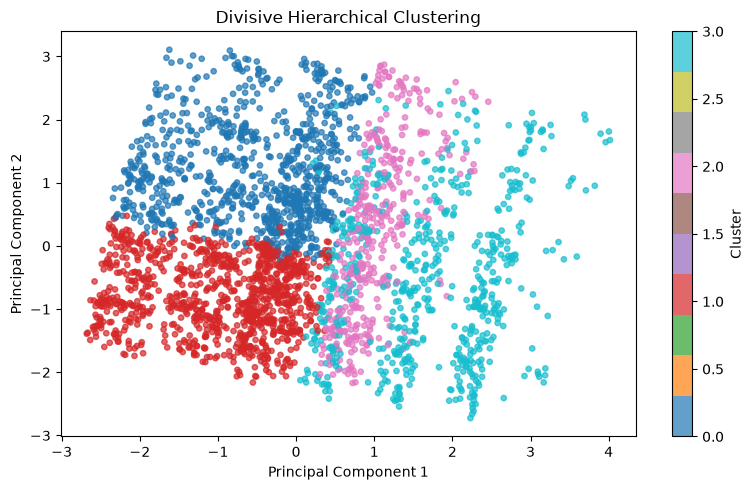

Algorithm: Divisive
Number of Clusters: 4
Noise Points: 0
Silhouette Score: 0.05591757274295183
Davies-Bouldin Index: 3.3111394811958084


In [107]:
def divisive_clustering(X, n_clusters=4):
    # Initially, all records belong to one cluster
    clusters = [np.arange(len(X))]

    while len(clusters) < n_clusters:

        # Find the cluster with the largest variation
        sse_values = []

        for indices in clusters:
            points = X[indices]
            center = points.mean(axis=0)
            sse = np.sum((points - center) ** 2)
            sse_values.append(sse if len(indices) > 1 else -1)

        cluster_idx = np.argmax(sse_values)

        # Remove the selected cluster
        indices = clusters.pop(cluster_idx)

        # Split it into two smaller clusters
        kmeans = KMeans(
            n_clusters=2,
            random_state=42,
            n_init=10
        )

        split_labels = kmeans.fit_predict(X[indices])

        left = indices[split_labels == 0]
        right = indices[split_labels == 1]

        clusters.extend([left, right])

    # Assign a final label to every record
    labels = np.zeros(len(X), dtype=int)

    for cluster_id, indices in enumerate(clusters):
        labels[indices] = cluster_id

    return labels


# Apply Divisive Clustering
divisive_labels = divisive_clustering(X, n_clusters=4)

# Plot clusters
plot_clusters(
    divisive_labels,
    "Divisive Hierarchical Clustering"
)

# Evaluate results
evaluate_model("Divisive", divisive_labels)

In [108]:
# Create comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Algorithm,Number of Clusters,Noise Points,Silhouette Score,Davies-Bouldin Index
0,K-Means,4,0,0.0771,2.8673
1,DBSCAN,13,2314,0.0061,1.9752
2,Agglomerative,4,0,0.0804,2.9509
3,Divisive,4,0,0.0559,3.3111


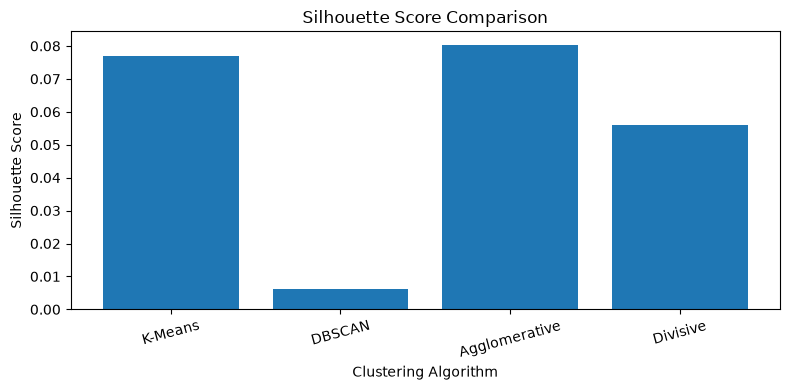

In [109]:
# Compare Silhouette Scores
plt.figure(figsize=(8, 4))

plt.bar(
    results_df["Algorithm"],
    results_df["Silhouette Score"]
)

plt.title("Silhouette Score Comparison")
plt.xlabel("Clustering Algorithm")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()